In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean aesthetic styling for our charts
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"

# 1. Define paths to our raw data files
DATA_DIR = r"C:\Users\SaiDivyashree\OneDrive\Desktop\Project_01_ProfitLens\Data\Raw\AdventureWorks-datasets-main"  # Or your full path: C:/Portfolio_Projects/Project_01_ProfitLens/data/raw

# 2. Load the Dimension Tables
print("Loading Dimension Tables...")
df_products = pd.read_csv(os.path.join(DATA_DIR, "AdventureWorks_Products.csv"))
df_subcategories = pd.read_csv(os.path.join(DATA_DIR, "AdventureWorks_Product_Subcategories.csv"))
df_categories = pd.read_csv(os.path.join(DATA_DIR, "AdventureWorks_Product_Categories.csv"))
df_returns = pd.read_csv(os.path.join(DATA_DIR, "AdventureWorks_Returns.csv"))

# 3. Load the 3 Partitioned Sales Files and Stack them (Like UNION ALL!)
print("Loading and Concatenating Sales Fact Tables...")
df_sales_2015 = pd.read_csv(os.path.join(DATA_DIR, "AdventureWorks_Sales_2015.csv"))
df_sales_2016 = pd.read_csv(os.path.join(DATA_DIR, "AdventureWorks_Sales_2016.csv"))
df_sales_2017 = pd.read_csv(os.path.join(DATA_DIR, "AdventureWorks_Sales_2017.csv"))

# pd.concat stacks the three years vertically into one master DataFrame
df_sales = pd.concat([df_sales_2015, df_sales_2016, df_sales_2017], ignore_index=True)

print(f"Total Sales Transactions Loaded: {len(df_sales):,}")
print(f"Total Products Loaded: {len(df_products):,}")

Loading Dimension Tables...
Loading and Concatenating Sales Fact Tables...
Total Sales Transactions Loaded: 56,046
Total Products Loaded: 293


In [3]:
# 1. Merge Sales with Product, Subcategory, and Category Dimensions (The Join Chain)
print("Merging tables...")
df_merged = df_sales.merge(df_products, on="ProductKey", how="inner")
df_merged = df_merged.merge(df_subcategories, on="ProductSubcategoryKey", how="inner")
df_merged = df_merged.merge(df_categories, on="ProductCategoryKey", how="inner")

# 2. Vectorized Financial Math (Calculating line-item economics)
df_merged["Revenue"] = df_merged["OrderQuantity"] * df_merged["ProductPrice"]
df_merged["Cost"] = df_merged["OrderQuantity"] * df_merged["ProductCost"]
df_merged["Profit"] = df_merged["Revenue"] - df_merged["Cost"]

# 3. Product-Level Aggregation (Like our SQL product_performance CTE)
df_product_summary = df_merged.groupby(
    ["ProductKey", "ProductName", "SubcategoryName", "CategoryName"]
).agg(
    UnitsSold=("OrderQuantity", "sum"),
    TotalRevenue=("Revenue", "sum"),
    TotalCost=("Cost", "sum"),
    TotalProfit=("Profit", "sum")
).reset_index()

# 4. Calculate Margin % for each product
df_product_summary["ProfitMarginPct"] = (
    df_product_summary["TotalProfit"] / df_product_summary["TotalRevenue"]
) * 100

# 5. Define the Business Quadrant Segment (Like CASE WHEN in SQL)
def classify_product(row):
    if row["TotalRevenue"] >= 500000 and row["ProfitMarginPct"] < 40.0:
        return "Profit Trap (High Rev, Low Margin)"
    elif row["TotalRevenue"] >= 500000 and row["ProfitMarginPct"] >= 40.0:
        return "Star (High Rev, High Margin)"
    elif row["TotalRevenue"] < 500000 and row["ProfitMarginPct"] >= 55.0:
        return "Cash Cow (Low Rev, High Margin)"
    else:
        return "Standard Performer"

df_product_summary["Segment"] = df_product_summary.apply(classify_product, axis=1)

print("Data processing complete! Here are the top 5 revenue products:")
df_product_summary.sort_values(by="TotalRevenue", ascending=False).head()

Merging tables...
Data processing complete! Here are the top 5 revenue products:


,ProductKey,ProductName,SubcategoryName,CategoryName,UnitsSold,TotalRevenue,TotalCost,TotalProfit,ProfitMarginPct,Segment
38,362,"Mountain-200 Black, 46",Mountain Bikes,Bikes,606,1.241754e+06,670120.8600,571632.6492,46.034309,"Star (High Rev, High Margin)"
37,360,"Mountain-200 Black, 42",Mountain Bikes,Bikes,602,1.233557e+06,665697.6200,567859.4964,46.034309,"Star (High Rev, High Margin)"
33,352,"Mountain-200 Silver, 38",Mountain Bikes,Bikes,586,1.213852e+06,655063.5574,558788.3282,46.034309,"Star (High Rev, High Margin)"
35,356,"Mountain-200 Silver, 46",Mountain Bikes,Bikes,571,1.182781e+06,638295.7189,544484.8727,46.034309,"Star (High Rev, High Margin)"
36,358,"Mountain-200 Black, 38",Mountain Bikes,Bikes,569,1.165937e+06,629205.8900,536730.9858,46.034309,"Star (High Rev, High Margin)"


C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\2250574760.py:46: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_xticklabels(['${:,.0f}'.format(x) for x in current_values])
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\2250574760.py:51: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\2250574760.py:51: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\2250574760.py:51: UserWarning: Glyph 128046 (\N{COW FACE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\2250574760.py:51: UserWarning: Glyph 10067 (\N{BLACK QUESTION MARK ORNAMENT}) missing from font(s) Arial.
  plt.tight_layo

Chart successfully saved as 'profitlens_strategic_quadrant_matrix.png'!


C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128046 (\N{COW FACE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10067 (\N{BLACK QUESTION MARK ORNAMENT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


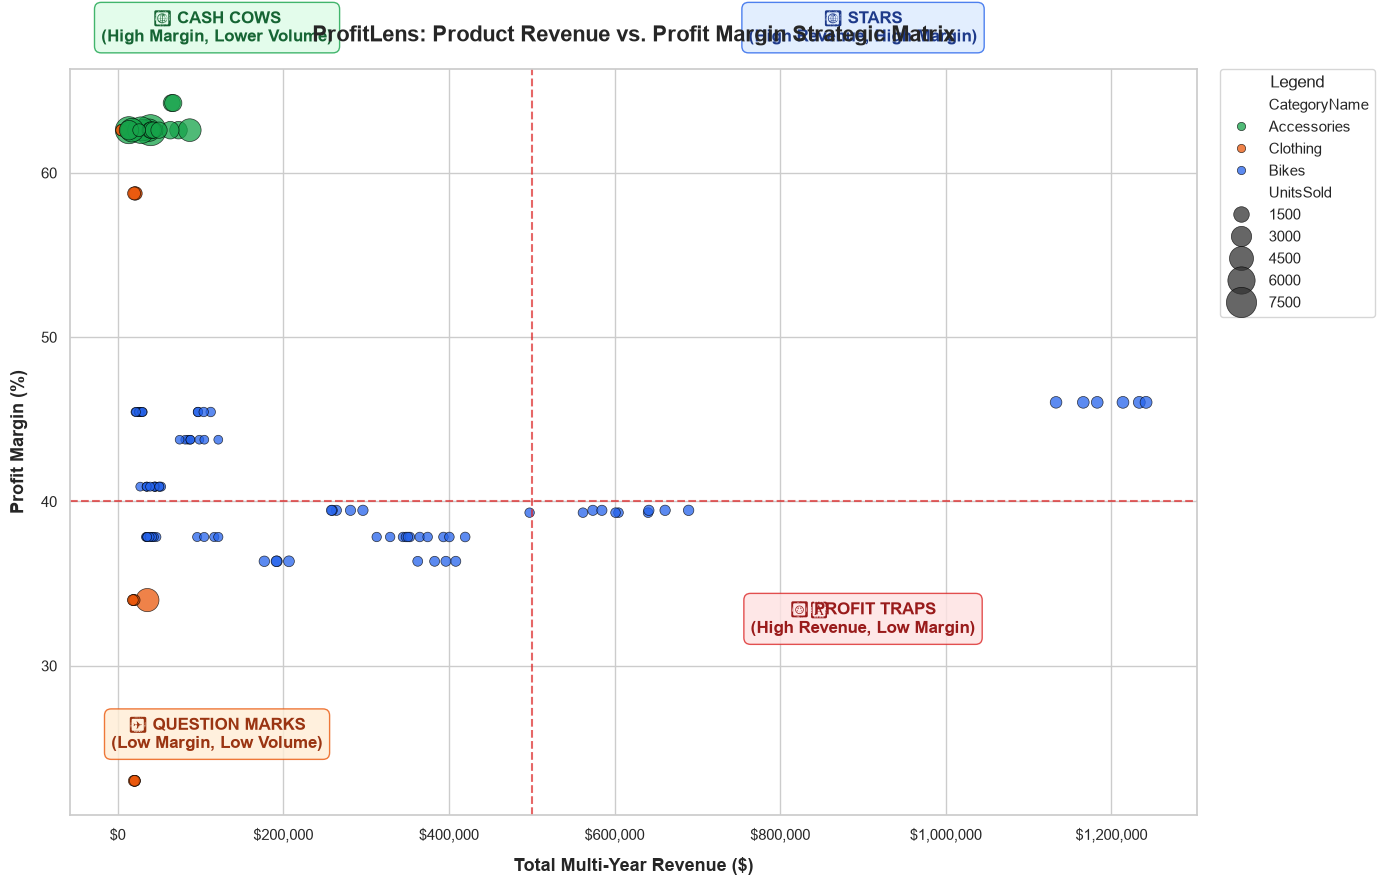

In [4]:
plt.figure(figsize=(14, 9))

# 1. Create the Scatter Plot
scatter = sns.scatterplot(
    data=df_product_summary,
    x="TotalRevenue",
    y="ProfitMarginPct",
    hue="CategoryName",
    size="UnitsSold",
    sizes=(40, 500),
    palette={"Bikes": "#2563eb", "Accessories": "#16a34a", "Clothing": "#ea580c"},
    alpha=0.75,
    edgecolor="black",
    linewidth=0.5
)

# 2. Add Benchmark Threshold Lines
plt.axvline(x=500000, color="#dc2626", linestyle="--", linewidth=1.5, alpha=0.7)
plt.axhline(y=40.0, color="#dc2626", linestyle="--", linewidth=1.5, alpha=0.7)

# 3. Label the 4 Strategic Quadrants
plt.text(900000, 68, "🌟 STARS\n(High Revenue, High Margin)", 
         fontsize=12, fontweight="bold", color="#1e3a8a", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#dbeafe", ec="#2563eb", alpha=0.8))

plt.text(900000, 32, "⚠️ PROFIT TRAPS\n(High Revenue, Low Margin)", 
         fontsize=12, fontweight="bold", color="#991b1b", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#fee2e2", ec="#dc2626", alpha=0.8))

plt.text(120000, 68, "🐮 CASH COWS\n(High Margin, Lower Volume)", 
         fontsize=12, fontweight="bold", color="#166534", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#dcfce7", ec="#16a34a", alpha=0.8))

plt.text(120000, 25, "❓ QUESTION MARKS\n(Low Margin, Low Volume)", 
         fontsize=12, fontweight="bold", color="#9a3412", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#ffedd5", ec="#ea580c", alpha=0.8))

# 4. Format Titles and Axis Labels
plt.title("ProfitLens: Product Revenue vs. Profit Margin Strategic Matrix", 
          fontsize=16, fontweight="bold", pad=20)
plt.xlabel("Total Multi-Year Revenue ($)", fontsize=13, fontweight="bold", labelpad=10)
plt.ylabel("Profit Margin (%)", fontsize=13, fontweight="bold", labelpad=10)

# Format X-axis to display clean currency ($) format
current_values = plt.gca().get_xticks()
plt.gca().set_xticklabels(['${:,.0f}'.format(x) for x in current_values])

# Improve Legend
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title="Legend", frameon=True)

plt.tight_layout()

# 5. Automatically Save the High-Resolution Chart for Portfolio & GitHub
plt.savefig("profitlens_strategic_quadrant_matrix.png", dpi=300, bbox_inches="tight")
print("Chart successfully saved as 'profitlens_strategic_quadrant_matrix.png'!")

plt.show()

C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\747301892.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  plt.gca().set_xticklabels(['${:,.0f}'.format(x) for x in current_values])
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\747301892.py:54: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\747301892.py:54: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\747301892.py:54: UserWarning: Glyph 128046 (\N{COW FACE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\SaiDivyashree\AppData\Local\Temp\ipykernel_78292\747301892.py:54: UserWarning: Glyph 10067 (\N{BLACK QUESTION MARK ORNAMENT}) missing from font(s) Arial.
  plt.tight_layout()


Chart successfully saved as 'profitlens_strategic_quadrant_matrix.png'!


C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128046 (\N{COW FACE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\SaiDivyashree\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10067 (\N{BLACK QUESTION MARK ORNAMENT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


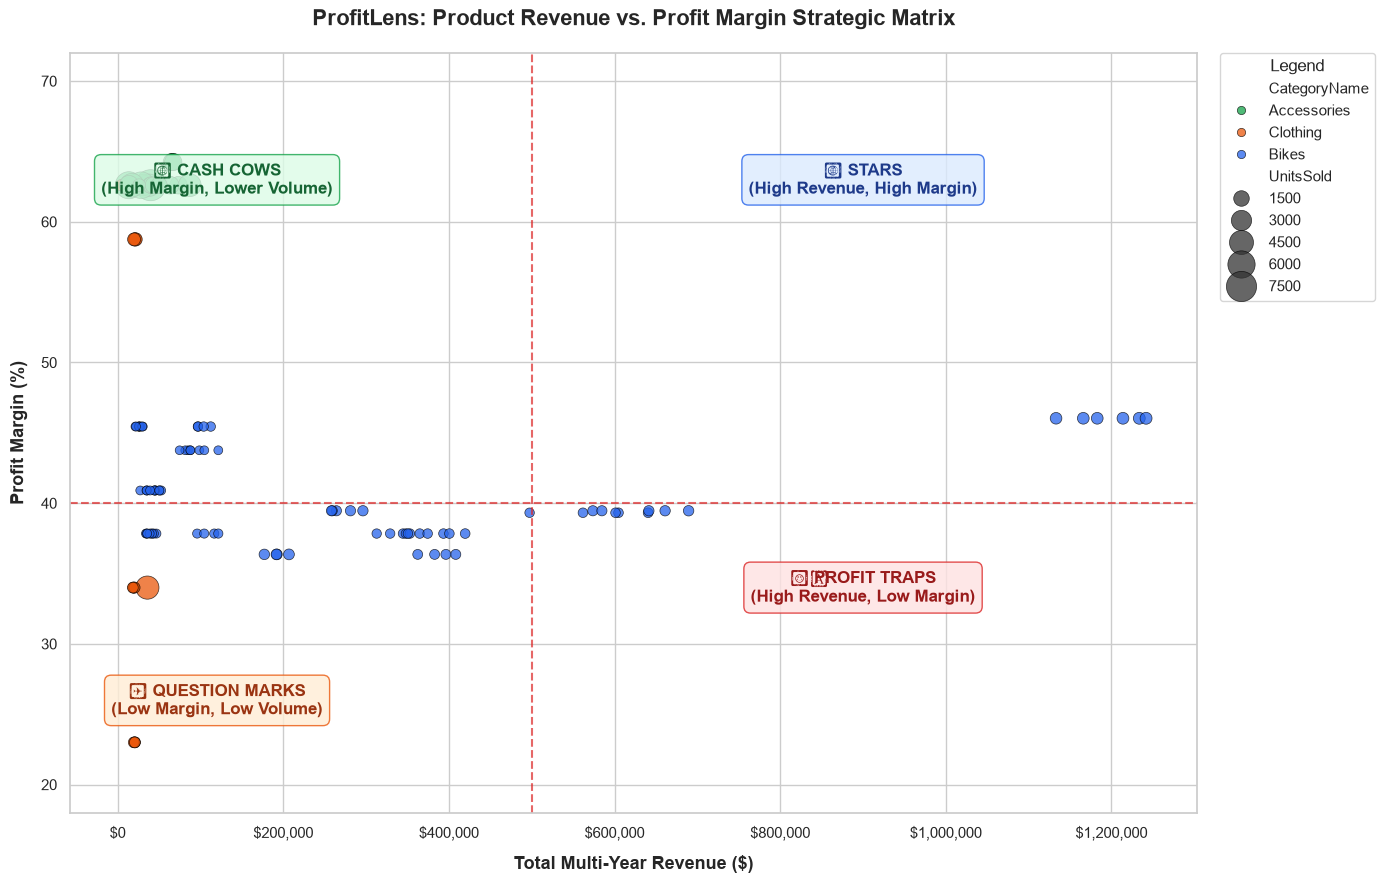

In [5]:
plt.figure(figsize=(14, 9))

# 1. Create the Scatter Plot
scatter = sns.scatterplot(
    data=df_product_summary,
    x="TotalRevenue",
    y="ProfitMarginPct",
    hue="CategoryName",
    size="UnitsSold",
    sizes=(40, 500),
    palette={"Bikes": "#2563eb", "Accessories": "#16a34a", "Clothing": "#ea580c"},
    alpha=0.75,
    edgecolor="black",
    linewidth=0.5
)

# Set Y-axis limits with comfortable breathing room at top and bottom
plt.ylim(18, 72)

# 2. Add Benchmark Threshold Lines
plt.axvline(x=500000, color="#dc2626", linestyle="--", linewidth=1.5, alpha=0.7)
plt.axhline(y=40.0, color="#dc2626", linestyle="--", linewidth=1.5, alpha=0.7)

# 3. Label the 4 Strategic Quadrants (Adjusted y-coordinates to prevent clipping)
plt.text(900000, 62, "🌟 STARS\n(High Revenue, High Margin)", 
         fontsize=12, fontweight="bold", color="#1e3a8a", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#dbeafe", ec="#2563eb", alpha=0.8))

plt.text(900000, 33, "⚠️ PROFIT TRAPS\n(High Revenue, Low Margin)", 
         fontsize=12, fontweight="bold", color="#991b1b", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#fee2e2", ec="#dc2626", alpha=0.8))

plt.text(120000, 62, "🐮 CASH COWS\n(High Margin, Lower Volume)", 
         fontsize=12, fontweight="bold", color="#166534", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#dcfce7", ec="#16a34a", alpha=0.8))

plt.text(120000, 25, "❓ QUESTION MARKS\n(Low Margin, Low Volume)", 
         fontsize=12, fontweight="bold", color="#9a3412", ha="center",
         bbox=dict(boxstyle="round,pad=0.4", fc="#ffedd5", ec="#ea580c", alpha=0.8))

# 4. Format Titles and Axis Labels
plt.title("ProfitLens: Product Revenue vs. Profit Margin Strategic Matrix", 
          fontsize=16, fontweight="bold", pad=20)
plt.xlabel("Total Multi-Year Revenue ($)", fontsize=13, fontweight="bold", labelpad=10)
plt.ylabel("Profit Margin (%)", fontsize=13, fontweight="bold", labelpad=10)

# Format X-axis to display clean currency ($) format
current_values = plt.gca().get_xticks()
plt.gca().set_xticklabels(['${:,.0f}'.format(x) for x in current_values])

# Improve Legend
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, title="Legend", frameon=True)

plt.tight_layout()

# 5. Automatically Save the High-Resolution Chart for Portfolio & GitHub
plt.savefig("profitlens_strategic_quadrant_matrix.png", dpi=300, bbox_inches="tight")
print("Chart successfully saved as 'profitlens_strategic_quadrant_matrix.png'!")

plt.show()